# `TreeCounterfactualExplainer`

`nife.counterfactual.TreeCounterfactualExplainer` explains a prediction with a surrogate decision tree, as proposed by Silva, Aguilar and Salvini (2026). A tree trained on the model's behavior around the instance shows the features that drive the prediction and the decision that would change it. NIFE turns that decision into counterfactuals that the model confirms, and supports the decision with evidence from the data.

What every counterfactual method has in common — the definition of a counterfactual and of its counterpart, the desired outcome, immutable features, selection, many instances and the `changes` plot — is in [counterfactual_explanations.ipynb](counterfactual_explanations.ipynb).

Requirements: `pip install "nife[notebooks]"`.

## An example

A random forest that classifies wines into three cultivars:

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier

from nife.counterfactual import TreeCounterfactualExplainer

X, y = load_wine(return_X_y=True, as_frame=True)
model = RandomForestClassifier(random_state=0).fit(X, y)

explainer = TreeCounterfactualExplainer(model, X, random_state=0)
explanation = explainer.explain(X.iloc[0])
print(explanation)

TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: color_intensity > 3.437 and proline > 651.7
  relevant features: proline, color_intensity, flavanoids
  counterfactual rule: proline > 651.7 -> proline <= 651.7 (not confirmed: changing proline alone keeps the model's prediction)
  counterfactuals: 16, changing 2 features each (16 copied from evidence examples)
  closest: malic_acid 1.71 -> 1.17, proline 1065 -> 510; predicted 1 (distance 0.039; counterpart at distance 0.137)
  evidence: 42 examples of the data on the other side of the rule, the closest at distance 0.176
  fidelity: instance agreement True, local fidelity 1.00 (neighborhood: around the instance, scale 1)


How to read it:

- **Decision path and relevant features.** A decision tree trained on the model's behavior around the wine predicts class 0 because `color_intensity > 3.437` and `proline > 651.7`.
- **Counterfactual rule.** In the tree, `proline ≤ 651.7` would lead to class 1. Here the model does not confirm the rule: lowering `proline` alone keeps its prediction.
- **Counterfactuals.** These are the smallest changes that the model does confirm. Each changes two features; the closest lowers `malic_acid` to 1.17 and `proline` to 510. Its counterpart, the closest real wine that the model puts in class 1, is at distance 0.137 from it.
- **Evidence.** The 42 real wines on the other side of the rule that the model puts in another class (class 1 or 2), the closest at distance 0.176 from the instance.
- **Fidelity.** The tree agrees with the model at the instance and on its 50 nearest examples, so its rules describe the model well around the wine.

The explanation keeps all of this in attributes:

| Attribute | What it is |
|---|---|
| `counterfactuals` | the counterfactuals, ranked by distance to the instance (see [the columns](counterfactual_explanations.ipynb#Explaining-an-instance)) |
| `crossed_rule` | the decision of the path to cross; `crossed_rule.inverted()` is the counterfactual rule |
| `crossed_rule_confirmed` | whether the model confirms the rule on the instance |
| `evidence` | the evidence of the rule: real examples on its other side with another outcome, the closest first |
| `evidence_candidates` | every example on the other side of the rule, with `is_evidence` |
| `rules` | the decision path, from the root to the leaf |
| `feature_importances` | the relevant features, by their importance in the tree |
| `surrogate` | the surrogate tree, a scikit-learn decision tree |
| `fidelity` | the agreement between the tree and the model |
| `neighborhood` | the perturbed neighborhood on which the tree was trained |

## How it works

`TreeCounterfactualExplainer` implements and extends the method of Silva, Aguilar and Salvini (2026):

1. **Neighborhood.** It samples a perturbed neighborhood of the instance, as LIME does, and labels it with the model's predictions.
2. **Surrogate tree.** A decision tree learns the model's behavior in that neighborhood. The features it uses, with their importances, are the **relevant features** of the prediction; the path of the instance from the root to its leaf is the **decision path**.
3. **Counterfactual rule.** Going up the decision path from the leaf, the first decision whose other side the tree gives another outcome is the one to cross (Algorithm 1 of the paper). Inverted, it is the counterfactual rule (`crossed_rule`), like the counterfactual rules of LORE (Guidotti et al., 2018), which also explains with a local decision tree. The rule comes from the tree, not from the model. `crossed_rule_confirmed` says whether the model confirms it on the instance, that is, whether moving only that feature to the other side changes the model's prediction.
4. **Counterfactuals.** The first candidate counterfactuals are the instance with a single feature moved to the other side of a decision of the path, starting with the counterfactual rule. Each feature takes the closest value of the data that the model confirms (`source="rule"`). When no single feature is enough, NIFE copies the fewest features from the closest evidence examples (`source="evidence"`), which is the idea of NICE (Brughmans et al., 2024). These counterfactuals are sparse and use values of real examples.
5. **Evidence of the rule.** These are the examples of the data on the other side of the counterfactual rule that the model gives another outcome (`evidence`, the closest first). The paper uses them to show that the new outcome is consistent with the data.

### Counterfactuals, counterparts and evidence

The instance, its closest counterfactual and the counterpart of that counterfactual, the closest real wine that the model puts in its class:

In [2]:
closest = explanation.counterfactuals.iloc[0]
print(f"counterpart: wine {closest['counterpart']}, at distance {closest['counterpart_distance']:.3f}")
pd.DataFrame({"instance": explanation.instance, "counterfactual": closest[X.columns],
              "counterpart": X.loc[closest["counterpart"]]})

counterpart: wine 66, at distance 0.137


,instance,counterfactual,counterpart
alcohol,14.23,14.23,13.11
malic_acid,1.71,1.17,1.01
ash,2.43,2.43,1.70
alcalinity_of_ash,15.60,15.6,15.00
magnesium,127.00,127.0,78.00
total_phenols,2.80,2.8,2.98
flavanoids,3.06,3.06,3.18
nonflavanoid_phenols,0.28,0.28,0.26
proanthocyanins,2.29,2.29,2.28
color_intensity,5.64,5.64,5.30


The counterfactual changes two features; its counterpart, a real wine, differs from the instance in almost all of them. The evidence of the rule, the closest first:

In [3]:
explanation.evidence.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,prediction,distance
66,13.11,1.01,1.70,15.0,78.0,2.98,3.18,0.26,2.28,5.30,1.12,3.18,502.0,1,0.175534
63,12.37,1.13,2.16,19.0,87.0,3.50,3.10,0.19,1.87,4.45,1.22,2.87,420.0,1,0.231015
126,12.43,1.53,2.29,21.5,86.0,2.74,3.15,0.39,1.77,3.94,0.69,2.84,352.0,1,0.236841
67,12.37,1.17,1.92,19.6,78.0,2.11,2.00,0.27,1.04,4.68,1.12,3.48,510.0,1,0.245112
72,13.49,1.66,2.24,24.0,87.0,1.88,1.84,0.27,1.03,3.74,0.98,2.78,472.0,1,0.247416


### A confirmed rule

For another wine, the model confirms the rule, and a single change is enough:

In [4]:
explainer.explain(X.iloc[30])

TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: color_intensity > 3.497 and proline > 757.1
  relevant features: color_intensity, proline, flavanoids, od280/od315_of_diluted_wines, alcohol
  counterfactual rule: proline > 757.1 -> proline <= 757.1 (confirmed by the model)
  counterfactuals: 1, changing 1 feature (1 crossing a decision of the path)
  closest: proline 1285 -> 570; predicted 1 (distance 0.039; counterpart at distance 0.105)
  evidence: 58 examples of the data on the other side of the rule, the closest at distance 0.154
  fidelity: instance agreement True, local fidelity 0.96 (neighborhood: around the instance, scale 1)

## Plots

Besides the `changes` plot of every counterfactual explanation (see [counterfactual_explanations.ipynb](counterfactual_explanations.ipynb#The-changes-plot)), the explanations of this method draw the relevant features and the tree.

**`importances`.** The features that the surrogate tree uses, ordered by importance. The feature of the counterfactual rule is in orange, the other features of the decision path in blue, and the remaining features of the tree in gray:

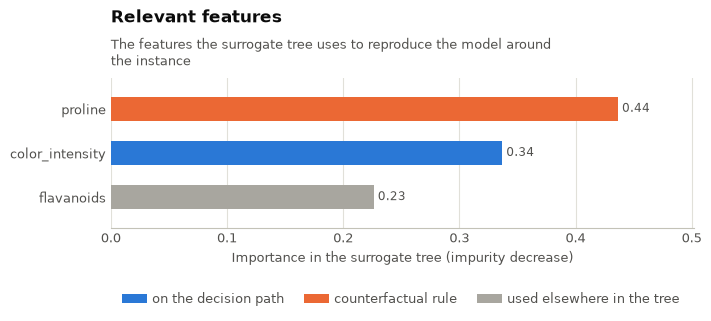

In [5]:
explanation.plot_importances();

**`tree`.** The surrogate tree, with the information of the trees in Silva, Aguilar and Salvini (2026). Each decision node shows its decision and its outcome (`value = …` in regression), each leaf its outcome, and the edges are `True` and `False`. The instance's decision path is in blue; the other side of the counterfactual rule, where its evidence lies, is in orange:

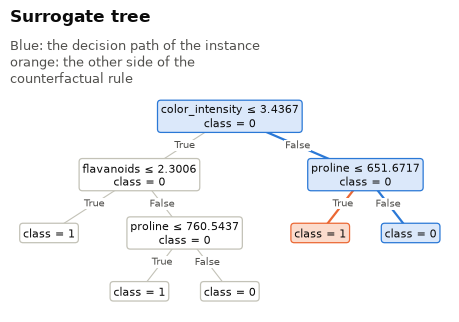

In [6]:
explanation.plot_tree();

The figure is compact, for papers: save it as vector graphics with `ax.figure.savefig("tree.pdf")`. `path_only=True` draws only the decision path, with the other side of each decision as a single node ("…" marks a subtree left out); it is the smallest figure, useful for deep trees. `titles=False` leaves out the title and subtitle, for a caption of your own; `precision` (4) is the number of decimals and `fontsize` (8) the size of the text:

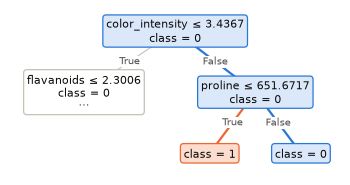

In [7]:
explanation.plot_tree(path_only=True, titles=False);

## Exporting the tree

`explanation.export_tree(format, path=None)` returns the surrogate tree as text in an established format, and writes it to `path` if given:

| Format | What it is | Read by |
|---|---|---|
| `"dot"` | [Graphviz DOT](https://graphviz.org), with the information and colors of `plot_tree` | Graphviz (`dot -Tpdf tree.dot -o tree.pdf`), and many tools that draw graphs |
| `"pmml"` | [PMML 4.4](https://dmg.org/pmml) `TreeModel`, the XML standard for exchanging predictive models: decisions, outcome and class distribution of each node; NIFE's decision path and the node on the other side of the counterfactual rule in `Extension` elements | PMML evaluators and tools such as KNIME, SAS, R and JPMML |
| `"text"` | the rules, as written by `sklearn.tree.export_text` | people, and anything that reads text |

In [8]:
print(explanation.export_tree("text"))

|--- color_intensity <= 3.436695
|   |--- flavanoids <= 2.300626
|   |   |--- class: 1
|   |--- flavanoids >  2.300626
|   |   |--- proline <= 760.543732
|   |   |   |--- class: 1
|   |   |--- proline >  760.543732
|   |   |   |--- class: 0
|--- color_intensity >  3.436695
|   |--- proline <= 651.671692
|   |   |--- class: 1
|   |--- proline >  651.671692
|   |   |--- class: 0



In [9]:
print(explanation.export_tree("dot"))

digraph surrogate_tree {
  node [shape=box, style="rounded,filled", fontname="Helvetica", fontsize=10, color="#c3c2b7", fillcolor="#ffffff"];
  edge [fontname="Helvetica", fontsize=9, color="#c3c2b7", arrowhead=none];
  0 [label="color_intensity ≤ 3.4367\nclass = 0", color="#2a78d6", fillcolor="#dbe8fa", penwidth=1.5];
  1 [label="flavanoids ≤ 2.3006\nclass = 0"];
  2 [label="class = 1"];
  3 [label="proline ≤ 760.5437\nclass = 0"];
  4 [label="class = 1"];
  5 [label="class = 0"];
  6 [label="proline ≤ 651.6717\nclass = 0", color="#2a78d6", fillcolor="#dbe8fa", penwidth=1.5];
  7 [label="class = 1", color="#eb6834", fillcolor="#fbdccd", penwidth=1.5];
  8 [label="class = 0", color="#2a78d6", fillcolor="#dbe8fa", penwidth=1.5];
  0 -> 1 [label="True"];
  0 -> 6 [label="False", color="#2a78d6", penwidth=2];
  1 -> 2 [label="True"];
  1 -> 3 [label="False"];
  3 -> 4 [label="True"];
  3 -> 5 [label="False"];
  6 -> 7 [label="True", color="#eb6834", penwidth=2];
  6 -> 8 [label="False", c

In [10]:
pmml = explanation.export_tree("pmml")  # or export_tree("pmml", "tree.pmml")
print(pmml[:1200], "...")

<?xml version="1.0" encoding="UTF-8"?>
<PMML xmlns="http://www.dmg.org/PMML-4_4" version="4.4">
  <Header description="Surrogate decision tree of a NIFE explanation">
    <Application name="NIFE" version="0.1.0"/>
  </Header>
  <DataDictionary numberOfFields="14">
    <DataField name="alcohol" optype="continuous" dataType="double"/>
    <DataField name="malic_acid" optype="continuous" dataType="double"/>
    <DataField name="ash" optype="continuous" dataType="double"/>
    <DataField name="alcalinity_of_ash" optype="continuous" dataType="double"/>
    <DataField name="magnesium" optype="continuous" dataType="double"/>
    <DataField name="total_phenols" optype="continuous" dataType="double"/>
    <DataField name="flavanoids" optype="continuous" dataType="double"/>
    <DataField name="nonflavanoid_phenols" optype="continuous" dataType="double"/>
    <DataField name="proanthocyanins" optype="continuous" dataType="double"/>
    <DataField name="color_intensity" optype="continuous" dataTy

## Options

- **Parameters of the tree**: `max_depth` is 5 by default, as in the paper; `min_samples_split` (0.1), `min_samples_leaf` (2) and `ccp_alpha` (0.02) default to the values of the original research (the paper keeps scikit-learn's defaults). Any other parameter of scikit-learn's decision trees goes in `tree_params`.
- **Immutable features** are also fixed in the neighborhood, so the tree only splits on the others.
- **Adaptive neighborhood** (default): the neighborhood starts narrow around the instance. It only widens until the tree has a counterfactual rule with evidence or a single-feature counterfactual, like the expanding spheres of Growing Spheres (Laugel et al., 2017). `adaptive=False` uses the global sample of the original method.
- **Fidelity** (`fidelity`): whether the tree gives the instance the same outcome as the model, and on what fraction of its 50 nearest examples (`fidelity_neighbors`) they agree. The rules only explain the prediction when the fidelity is high. `fidelity_table` gathers the fidelity of many explanations.
- **Neighborhood** (`neighborhood`, `neighborhood=`, `sampler=`): extract the neighborhood of an explanation, or use your own; see [TreeCounterfactualExplainer_neighborhood.ipynb](TreeCounterfactualExplainer_neighborhood.ipynb).

### Regression, with a desired outcome and immutable features

A random forest that predicts the progression of diabetes one year ahead (the diabetes dataset bundled with scikit-learn; the features are standardized). Age and sex cannot change, and the counterfactuals should lower the predicted progression:

In [11]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor

X, y = load_diabetes(return_X_y=True, as_frame=True)
model = RandomForestRegressor(random_state=0).fit(X, y)

explainer = TreeCounterfactualExplainer(
    model, X, mode="regression", categorical_features=["sex"], immutable_features=["age", "sex"], random_state=0
)
explanation = explainer.explain(X.iloc[0], desired="lower")
explanation

TreeCounterfactualExplanation (regression) of an instance predicted 175.48, desired 'lower'
  decision path: bmi <= 0.06738 and s5 > -0.003059 and bp <= 0.02349 and s5 <= 0.03276
  relevant features: bmi, s5, bp
  counterfactual rule: s5 > -0.003059 -> s5 <= -0.003059 (confirmed by the model)
  counterfactuals: 1, changing 1 feature (1 crossing a decision of the path)
  closest: s5 0.01991 -> -0.04398; predicted 166.15 (distance 0.025; counterpart at distance 0.054)
  evidence: 189 examples of the data on the other side of the rule, the closest at distance 0.059
  fidelity: instance agreement True, local fidelity 0.26 (neighborhood: around the instance, scale 1)

In [12]:
explanation.counterfactuals

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,prediction,source,distance,changed_features,counterpart,counterpart_distance
0,0.038076,0.05068,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,-0.043984,-0.017646,166.15,rule,0.024602,1,271,0.053923


### Fidelity and the adaptive neighborhood

The rules only explain the prediction if the tree agrees with the model around the instance. `explanation.fidelity` reports whether it gives the instance the same outcome and the fraction of its 50 nearest examples on which they agree (within 5%, in regression):

In [13]:
explanation.fidelity

rules                              4
model_prediction              175.48
surrogate_prediction      172.571498
instance_agreement              True
local_fidelity                  0.26
neighborhood                 sampled
sample_around_instance          True
neighborhood_scale               1.0
dtype: object

The adaptive neighborhood and the global sample of the original method, over 20 patients:

In [14]:
from nife.counterfactual.tree import fidelity_table

instances = X.sample(20, random_state=0)
rows = {}
for name, adaptive in [("adaptive (default)", True), ("global sample", False)]:
    options = dict(mode="regression", categorical_features=["sex"], adaptive=adaptive, random_state=0)
    _, explanations = TreeCounterfactualExplainer(model, X, **options).explain_many(instances, return_explanations=True)
    fidelity = fidelity_table(explanations)
    rows[name] = fidelity[["rules", "instance_agreement", "local_fidelity"]].mean()
pd.DataFrame(rows)

,adaptive (default),global sample
rules,4.900,4.100
instance_agreement,0.550,0.100
local_fidelity,0.136,0.122


The adaptive neighborhood makes the tree agree with the model at the instance more often, but here the tree rarely stays within 5% of the forest on the nearest examples: a small tree follows a regression forest only roughly. Check the fidelity before reading the rules as the reasons for a prediction; the counterfactuals themselves are always confirmed by the model.

## Reproducing the paper

The results of the paper use the original method: a global neighborhood (`adaptive=False`), a tree of depth 3 in classification (5 in regression) and LightGBM models. The other parameters of the tree are the defaults of NIFE. The fidelity of the paper is the agreement of the tree with the model on the whole dataset, averaged over the explained instances. The default `max_depth` of NIFE is 5, the value in the text of the paper; the classification results of its tables come from depth 3.

```python
import numpy as np
import lightgbm as lgb  # pip install lightgbm
from sklearn.datasets import load_iris

X, y = load_iris(return_X_y=True, as_frame=True)
model = lgb.LGBMClassifier(verbose=-1, random_state=0).fit(X, y)
predictions = model.predict(X)

explainer = TreeCounterfactualExplainer(
    model, X, adaptive=False, max_depth=3, random_state=np.random.RandomState(1)
)
fidelity = [
    np.mean(explainer.explain(X.iloc[i]).surrogate.predict(X.to_numpy().astype(np.float32)) == predictions)
    for i in range(150)
]
print(np.mean(fidelity))  # 0.959 here; 0.957 in the paper
```

With the wine dataset the same code gives 0.947 (0.951 in the paper). The exact digits depend on the random samples, and the fidelity depends on the model: the global neighborhood reaches far from the data, where models of other families (a random forest, for example) behave differently.


## How to cite

If you use this method, please cite the paper that introduced it, besides NIFE itself (see the [README](../../README.md#how-to-cite)):

```bibtex
@inproceedings{silva2026unveiling,
  author    = {Silva, Jurandir and Aguilar, Eduardo and Salvini, Rogerio},
  title     = {Unveiling Concise Counterfactual Explanations and Feature Relevance in Machine Learning through Decision Trees},
  booktitle = {Proceedings of the 18th International Conference on Agents and Artificial Intelligence (ICAART 2026) - Volume 4},
  pages     = {2941--2948},
  year      = {2026},
  publisher = {SciTePress},
  doi       = {10.5220/0014338700004052},
  isbn      = {978-989-758-796-2},
  issn      = {2184-433X}
}
```

## References

- Brughmans, D., Leyman, P., & Martens, D. (2024). NICE: an algorithm for nearest instance counterfactual explanations. *Data Mining and Knowledge Discovery*, 38(5), 2665–2703. https://doi.org/10.1007/s10618-023-00930-y
- Guidotti, R., Monreale, A., Ruggieri, S., Pedreschi, D., Turini, F., & Giannotti, F. (2018). Local rule-based explanations of black box decision systems. *arXiv:1805.10820*.
- Laugel, T., Lesot, M.-J., Marsala, C., Renard, X., & Detyniecki, M. (2017). Inverse classification for comparison-based interpretability in machine learning. *arXiv:1712.08443*.
- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. *Proceedings of the 22nd ACM SIGKDD*, 1135–1144.
- Silva, J., Aguilar, E., & Salvini, R. (2026). Unveiling concise counterfactual explanations and feature relevance in machine learning through decision trees. *ICAART 2026*, 2941–2948. https://doi.org/10.5220/0014338700004052